# Задача №12. Нижние оценки для задачи коммивояжёра

**Условие:** сравнить не менее четырёх нижних оценок для задачи коммивояжёра на примере `tsp.txt`.

Рассмотрим шесть оценок. Часть из них описана в **лекции №9 «Задача коммивояжёра. Часть 2»** (примитивная оценка, 1-дерево, задача о назначениях). Дополнительно используем оценки по двум рёбрам, по минимальному остову и усиление 1-дерева методом Хелда–Карпа. Для контроля сравним их с известным оптимумом экземпляра.

Файл `tsp.txt` должен находиться **в той же директории, что и ноутбук**. Данные из файла не встраиваются в код.

## Постановка задачи

Пусть $V=\{1,\ldots,n\}$ — множество городов, $c_{ij}=c_{ji}$ — стоимость перехода между городами $i$ и $j$. Требуется найти гамильтонов цикл минимальной длины:

$$
\operatorname{OPT}=\min_{\pi}\; F(\pi),\qquad
F(\pi)=\sum_{k=1}^{n}c_{\pi_k,\pi_{k+1}},\qquad \pi_{n+1}=\pi_1.
$$

**Нижняя оценка** $LB$ должна удовлетворять $LB\leq \operatorname{OPT}$. Чем больше корректная нижняя оценка, тем она точнее.

В файле задан формат `EUC_2D`: расстояние вычисляется по евклидовой метрике с округлением до ближайшего целого согласно TSPLIB, т. е. $c_{ij}=\lfloor\sqrt{(x_i-x_j)^2+(y_i-y_j)^2}+0.5\rfloor$. Обычные неокруглённые расстояния дали бы другую задачу.

In [1]:
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment


def load_tsp(path=Path("tsp.txt")):
    if not path.exists():
        raise FileNotFoundError(f"Не найден {path.resolve()}. Положите tsp.txt рядом с ноутбуком.")

    meta, coords = {}, []
    reading_coords = False
    for raw in path.read_text(encoding="utf-8-sig").splitlines():
        line = raw.strip()
        if not line:
            continue
        if line.upper() == "NODE_COORD_SECTION":
            reading_coords = True
            continue
        if line.upper() == "EOF":
            break
        if reading_coords:
            parts = line.split()
            if len(parts) != 3:
                raise ValueError(f"Некорректная строка координат: {line}")
            coords.append((int(parts[0]), float(parts[1]), float(parts[2])))
        elif ":" in line:
            key, value = line.split(":", 1)
            meta[key.strip().upper()] = value.strip()

    if meta.get("TYPE") != "TSP" or meta.get("EDGE_WEIGHT_TYPE") != "EUC_2D":
        raise ValueError("Этот ноутбук рассчитан на симметричный TSP с EDGE_WEIGHT_TYPE: EUC_2D")
    if len(coords) != int(meta["DIMENSION"]):
        raise ValueError("Число координат не совпадает с DIMENSION")

    node_ids = np.array([t[0] for t in coords], dtype=int)
    if len(set(node_ids)) != len(node_ids):
        raise ValueError("В файле повторяются номера городов")
    xy = np.array([(x, y) for _, x, y in coords], dtype=float)
    dx = xy[:, 0, None] - xy[None, :, 0]
    dy = xy[:, 1, None] - xy[None, :, 1]
    c = np.floor(np.hypot(dx, dy) + 0.5).astype(np.int64)
    np.fill_diagonal(c, 0)
    return meta, node_ids, xy, c


meta, node_ids, xy, c = load_tsp()
n = len(c)
assert np.array_equal(c, c.T) and np.all(np.diag(c) == 0)
print(f"Тест: {meta['NAME']}; городов: {n}; тип расстояний: {meta['EDGE_WEIGHT_TYPE']}")

Тест: pbl395; городов: 395; тип расстояний: EUC_2D


## Нижние оценки

1. **Примитивная оценка (лекция №9, слайд 1).** Вычитаем из каждой строки матрицы её минимум $a_i=\min_{j\ne i}c_{ij}$, а затем из каждого столбца остаточной матрицы минимум $b_j=\min_{i\ne j}(c_{ij}-a_i)$:

   $$LB_{\mathrm{prim}}=\sum_i a_i+\sum_j b_j.$$

   В любом туре из каждого города есть один выход и один вход, поэтому это нижняя оценка.

2. **Два минимальных ребра.** Пусть $c_i^{(1)},c_i^{(2)}$ — два наименьших веса рёбер, инцидентных вершине $i$. В туре степень каждой вершины равна двум:

   $$LB_{\mathrm{2edge}}=\frac12\sum_{i\in V}\bigl(c_i^{(1)}+c_i^{(2)}\bigr).$$

3. **Минимальное остовное дерево (MST).** Удаление любого ребра из тура даёт остовное дерево, поэтому

   $$LB_{\mathrm{MST}}=w(\operatorname{MST}(V)).$$

4. **Минимальное 1-дерево (лекция №9, слайд 3).** Выберем вершину $r$. Построим минимальный остов на $V\setminus\{r\}$ и добавим к $r$ два различных самых дешёвых ребра:

   $$LB_{\mathrm{1tree}}=w(\operatorname{MST}(V\setminus\{r\}))+c_r^{(1)}+c_r^{(2)}.$$

   Любой гамильтонов цикл является 1-деревом, следовательно, минимальное 1-дерево не дороже оптимального тура.

5. **Задача о назначениях (лекция №9, слайд 4).** Расслабим требование единственного цикла: оставим по одному входу и выходу для каждого города, разрешив несколько подциклов:

   $$LB_{\mathrm{assign}}=\min\sum_{i\ne j}c_{ij}x_{ij},\qquad
   \sum_{j\ne i}x_{ij}=1,\quad\sum_{i\ne j}x_{ij}=1,\quad x_{ij}\in\{0,1\}.$$

   Допустимых решений становится больше, поэтому оптимум задачи о назначениях не превосходит оптимум TSP.

In [2]:
def primitive_bound(c):
    w = c.astype(float).copy()
    np.fill_diagonal(w, np.inf)  # Запрещаем переход i -> i
    row_min = w.min(axis=1)
    col_min = (w - row_min[:, None]).min(axis=0)
    return float(row_min.sum() + col_min.sum())


def two_edges_bound(c):
    w = c.astype(float).copy()
    np.fill_diagonal(w, np.inf)
    two_smallest = np.partition(w, kth=1, axis=1)[:, :2]
    return float(two_smallest.sum() / 2)


def prim_mst(w):
    """Алгоритм Прима: вес MST и список его рёбер (для матрицы весов)."""
    m = len(w)
    used = np.zeros(m, dtype=bool)
    used[0] = True
    best = w[0].copy()
    best[0] = np.inf
    parent = np.zeros(m, dtype=int)
    edges = []
    total = 0.0

    for _ in range(m - 1):
        v = int(np.argmin(best))
        if not np.isfinite(best[v]):
            raise ValueError("Граф не является связным")
        total += best[v]
        edges.append((int(parent[v]), v))
        used[v] = True
        update = (~used) & (w[v] < best)
        best[update] = w[v, update]
        parent[update] = v
        best[v] = np.inf
    return total, np.array(edges, dtype=int)


def mst_bound(c):
    w = c.astype(float).copy()
    np.fill_diagonal(w, np.inf)
    return prim_mst(w)[0]

In [3]:
def one_tree_bound(c, pi=None, root=0):
    """Нижняя оценка через 1-дерево; pi — потенциалы вершин."""
    n = len(c)
    if pi is None:
        pi = np.zeros(n, dtype=float)

    w = c.astype(float) + pi[:, None] + pi[None, :]
    np.fill_diagonal(w, np.inf)
    others = np.array([i for i in range(n) if i != root], dtype=int)

    mst_weight, local_edges = prim_mst(w[np.ix_(others, others)])
    root_neighbors = others[np.argpartition(w[root, others], kth=1)[:2]]
    edges = np.vstack((
        others[local_edges],
        np.column_stack((np.full(2, root), root_neighbors))
    ))
    degrees = np.bincount(edges.ravel(), minlength=n)
    modified_weight = mst_weight + w[root, root_neighbors].sum()

    # Для любого тура сумма степеней с весами pi равна 2*sum(pi).
    bound = float(modified_weight - 2 * pi.sum())
    return bound, degrees, edges


def assignment_bound(c):
    w = c.astype(float).copy()
    np.fill_diagonal(w, np.inf)
    rows, cols = linear_sum_assignment(w)
    return float(w[rows, cols].sum()), cols

### Усиление 1-дерева: оценка Хелда–Карпа

У обычного 1-дерева все веса исходные. Можно добавить каждой вершине потенциал $\pi_i$ и рассматривать модифицированные веса $\widetilde c_{ij}=c_{ij}+\pi_i+\pi_j$. Тогда

$$LB_{HK}(\pi)=\min_{T\text{ — 1-дерево}}\sum_{(i,j)\in T}\widetilde c_{ij}-2\sum_i\pi_i\leq\operatorname{OPT}.$$

Поскольку в любом туре степень каждой вершины равна двум, оценка корректна **при любых** $\pi$. Подбираем потенциалы методом субградиента: $\pi_i\leftarrow\pi_i+t(\deg_T(i)-2)$ и запоминаем наибольшую полученную нижнюю оценку. Это **приближённое усиление** 1-дерева, а не точное решение TSP.

Для подбора шага нужен верхний предел $UB$, т. е. длина любого допустимого тура. Получим её из алгоритма ближайшего соседа и локального спуска с 2-заменой из лекции №8. **$UB$ — верхняя, а не нижняя оценка.**

In [4]:
def tour_length(tour, c):
    return int(c[tour, np.roll(tour, -1)].sum())


def nearest_neighbor(c, start=0):
    n = len(c)
    used = np.zeros(n, dtype=bool)
    tour = np.empty(n, dtype=int)
    v = start
    for k in range(n):
        tour[k] = v
        used[v] = True
        if k < n - 1:
            costs = np.where(used, np.inf, c[v].astype(float))
            v = int(np.argmin(costs))
    return tour


def local_2opt(tour, c):
    """Стандартный локальный спуск: выбираем наилучшую улучшающую 2-замену."""
    tour = tour.copy()
    n = len(tour)
    while True:
        best_delta, best_pair = 0, None
        for i in range(1, n - 1):
            js = np.arange(i + 1, n)
            a, b = tour[i - 1], tour[i]
            cc, d = tour[js], tour[(js + 1) % n]
            deltas = c[a, cc] + c[b, d] - c[a, b] - c[cc, d]
            t = int(np.argmin(deltas))
            if deltas[t] < best_delta:
                best_delta = int(deltas[t])
                best_pair = (i, int(js[t]))
        if best_pair is None:
            break
        i, j = best_pair
        tour[i:j+1] = tour[i:j+1][::-1]
    return tour, tour_length(tour, c)


def held_karp_bound(c, ub, root=0, iterations=250):
    pi = np.zeros(len(c), dtype=float)
    best_lb = -np.inf
    step_scale = 1.5
    without_improvement = 0
    history = []

    for _ in range(iterations):
        lb, degrees, _ = one_tree_bound(c, pi=pi, root=root)
        if lb > best_lb + 1e-8:
            best_lb = lb
            without_improvement = 0
        else:
            without_improvement += 1
        history.append(best_lb)

        g = degrees - 2
        norm2 = float(g @ g)
        if norm2 == 0:  # 1-дерево уже является гамильтоновым циклом
            break
        step = step_scale * max(ub - lb, 0.0) / norm2
        pi += step * g
        if without_improvement >= 20:
            step_scale *= 0.6
            without_improvement = 0
        if step_scale < 0.005:
            break

    return float(best_lb), history

## Вычислительный эксперимент

Сначала построим допустимый тур для верхней оценки. Затем вычислим **все шесть нижних оценок** на одной и той же матрице $c$ и сравним с опубликованным оптимумом для `pbl395`:

$$\operatorname{OPT}=1281.$$

Источник подтверждённого оптимума: [University of Waterloo — Status of VLSI TSP Instances](https://math.uwaterloo.ca/tsp/vlsi/summary.html). Для другого теста значение `KNOWN_OPT` необходимо заменить на его собственный доказанный оптимум (либо не использовать сравнение с оптимумом).

In [5]:
# Несколько начальных городов уменьшают зависимость верхней оценки от старта.
starts = [0, n // 4, n // 2, 3 * n // 4]
upper_results = []
for start in starts:
    initial = nearest_neighbor(c, start=start)
    improved, length = local_2opt(initial, c)
    upper_results.append((length, improved))

UB, best_tour = min(upper_results, key=lambda item: item[0])
assert sorted(best_tour.tolist()) == list(range(n))
print(f"Верхняя оценка (ближайший сосед + локальный спуск 2-opt): UB = {UB}")

Верхняя оценка (ближайший сосед + локальный спуск 2-opt): UB = 1333


In [6]:
# Время вычисления измеряем одинаково для всех методов.
results = []

def measure(label, fn):
    started = perf_counter()
    value = float(fn())
    results.append({"Оценка": label, "LB": value, "Время, с": perf_counter() - started})

measure("Примитивная (вход/выход)", lambda: primitive_bound(c))
measure("Два минимальных ребра", lambda: two_edges_bound(c))
measure("Минимальное остовное дерево", lambda: mst_bound(c))
measure("Минимальное 1-дерево", lambda: one_tree_bound(c, root=0)[0])
measure("Задача о назначениях", lambda: assignment_bound(c)[0])

start_hk = perf_counter()
hk_lb, hk_history = held_karp_bound(c, ub=UB, root=0, iterations=250)
results.append({"Оценка": "1-дерево с потенциалами (Хелд–Карп)",
                "LB": hk_lb, "Время, с": perf_counter() - start_hk})

KNOWN_OPT = 1281 if meta["NAME"].lower() == "pbl395" else None
if KNOWN_OPT is None:
    raise ValueError("Известный оптимум задан только для pbl395; укажите оптимум текущего теста")

assert all(item["LB"] <= KNOWN_OPT + 1e-7 for item in results), "Некорректная нижняя оценка"
assert KNOWN_OPT <= UB, "Полученная длина тура меньше опубликованного оптимума"

comparison = pd.DataFrame(results)
comparison["Разница с OPT"] = KNOWN_OPT - comparison["LB"]
comparison["Отставание от OPT, %"] = 100 * comparison["Разница с OPT"] / KNOWN_OPT
comparison = comparison.sort_values("LB", ascending=False).reset_index(drop=True)
display(comparison.round({"LB": 3, "Время, с": 4,
                          "Разница с OPT": 3, "Отставание от OPT, %": 2}))
print(f"Доказанный оптимум: {KNOWN_OPT}; полученная верхняя оценка: {UB}")

,Оценка,LB,"Время, с",Разница с OPT,"Отставание от OPT, %"
0,1-дерево с потенциалами (Хелд–Карп),1269.803,2.1788,11.197,0.87
1,Минимальное 1-дерево,1134.000,0.0082,147.000,11.48
2,Минимальное остовное дерево,1124.000,0.0062,157.000,12.26
3,Два минимальных ребра,1035.000,0.0017,246.000,19.20
4,Задача о назначениях,1003.000,0.0052,278.000,21.70
5,Примитивная (вход/выход),949.000,0.0017,332.000,25.92


Доказанный оптимум: 1281; полученная верхняя оценка: 1333


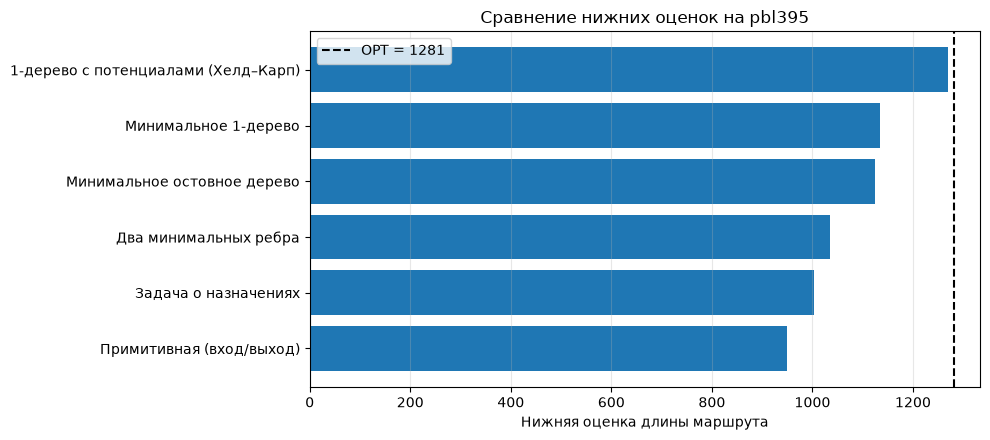

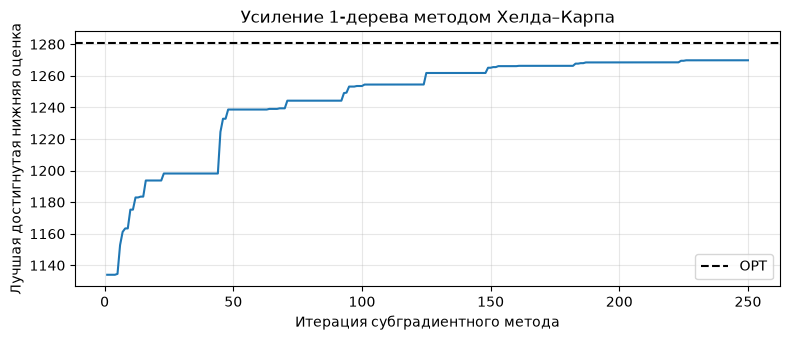

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
chart = comparison.sort_values("LB")
ax.barh(chart["Оценка"], chart["LB"])
ax.axvline(KNOWN_OPT, color="black", linestyle="--", label=f"OPT = {KNOWN_OPT}")
ax.set_xlabel("Нижняя оценка длины маршрута")
ax.set_title(f"Сравнение нижних оценок на {meta['NAME']}")
ax.legend()
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(range(1, len(hk_history) + 1), hk_history)
ax.axhline(KNOWN_OPT, color="black", linestyle="--", label="OPT")
ax.set_xlabel("Итерация субградиентного метода")
ax.set_ylabel("Лучшая достигнутая нижняя оценка")
ax.set_title("Усиление 1-дерева методом Хелда–Карпа")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Выводы

Все шесть методов выдали нижние оценки, не превосходящие доказанный оптимум $1281$. Примитивная оценка и задача о назначениях особенно просты, но разрешают слишком много решений, которые не являются гамильтоновыми циклами. Оценка по минимальному остову усиливается добавлением двух рёбер выделенной вершины (1-дерево).

**На данном экземпляре самой сильной оказалась оценка Хелда–Карпа**: подбор потенциалов позволил заметно улучшить обычное 1-дерево. При этом вычисление потребовало больше времени, чем элементарные оценки. Для подтверждения корректности использовали не эвристическое решение, а опубликованный оптимум и неравенство

$$\max\{LB_1,\ldots,LB_6\}\leq \operatorname{OPT}\leq UB.$$

Методы и терминология: **лекция №9, слайды 1–4** (примитивная оценка, 1-дерево, назначения), **лекция №8, слайды 11–14** (локальный спуск, ближайший сосед). Усиление потенциалами — дополнительный метод Хелда–Карпа ([Held & Karp, 1970](https://doi.org/10.1287/opre.18.6.1138)).